In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('titanic.csv')
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df['Mujer'] = (df['Sex'] == 'female').astype(int)
df['Age'] = df['Age'].fillna(df['Age'].median())

variables = ['Pclass','Mujer','Age','Fare']
df[variables].describe()

,Pclass,Mujer,Age,Fare
count,891.000000,891.000000,891.000000,891.000000
mean,2.308642,0.352413,29.361582,32.204208
std,0.836071,0.477990,13.019697,49.693429
min,1.000000,0.000000,0.420000,0.000000
25%,2.000000,0.000000,22.000000,7.910400
50%,3.000000,0.000000,28.000000,14.454200
75%,3.000000,1.000000,35.000000,31.000000
max,3.000000,1.000000,80.000000,512.329200


In [5]:
datos = df[variables]
X = ((datos - datos.mean()) / datos.std()).values #values convierte en mtriz de numpy
print(X.shape)  # (pasajeros,variables)



(891, 4)


In [6]:
def mi_kmeans(X, k, semilla=0, max_vueltas=50):
    np. random.seed(semilla)

    posiciones = np.random.choice(len(X), k, replace=False)
    centroides = X[posiciones]

    for vuelta in range(max_vueltas):
        # Asignar cada punto al centroide más cercano
        distancias = np.zeros((len(X), k))
        for j in range(k):
            distancias[:, j] = np.sqrt(((X - centroides[j] ** 2).sum(axis=1)))

            grupos = distancias.argmin(axis=1)

            nuevos = np.array([X[grupos == j].mean(axis=0) for j in range(k)])

            if np.allclose(nuevos,centroides):
                break
            centroides = nuevos

            return grupos, centroides

C:\Users\Luiso\AppData\Local\Temp\ipykernel_12932\3489298937.py:11: RuntimeWarning: invalid value encountered in sqrt
  distancias[:, j] = np.sqrt(((X - centroides[j] ** 2).sum(axis=1)))
C:\Users\Luiso\AppData\Local\Temp\ipykernel_12932\3489298937.py:15: RuntimeWarning: Mean of empty slice
  nuevos = np.array([X[grupos == j].mean(axis=0) for j in range(k)])
d:\vvv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


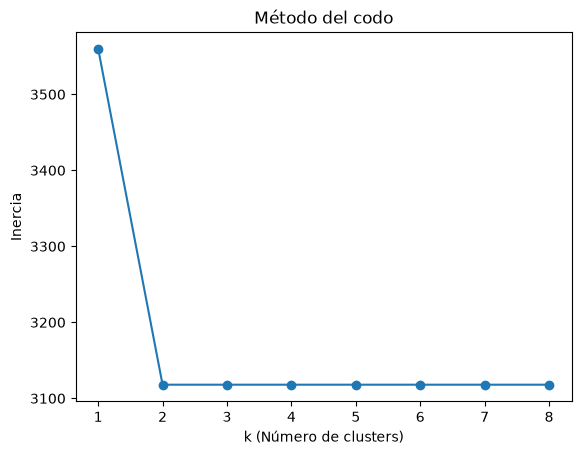

In [9]:


def inercia(X, grupos, centroides):
    total = 0
    for j in range(len(centroides)):
        total += ((X[grupos == j] - centroides[j]) ** 2).sum()
    return total

valores_k = range(1, 9)
inercias = []

# 1. Calculamos las inercias para todos los valores de k
for k in valores_k:
    grupos, centroides = mi_kmeans(X, k)
    inercias.append(inercia(X, grupos, centroides))

# 2. Graficamos una vez completado el bucle
plt.plot(valores_k, inercias, 'o-')
plt.xlabel('k (Número de clusters)')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.show()

In [10]:
K = 3
grupos, centroides = mi_kmeans(X, K)

df['grupo'] = grupos
df['grupo'].value_counts().sort_index()


C:\Users\Luiso\AppData\Local\Temp\ipykernel_12932\3489298937.py:11: RuntimeWarning: invalid value encountered in sqrt
  distancias[:, j] = np.sqrt(((X - centroides[j] ** 2).sum(axis=1)))
C:\Users\Luiso\AppData\Local\Temp\ipykernel_12932\3489298937.py:15: RuntimeWarning: Mean of empty slice
  nuevos = np.array([X[grupos == j].mean(axis=0) for j in range(k)])


grupo
0    725
1    166
Name: count, dtype: int64

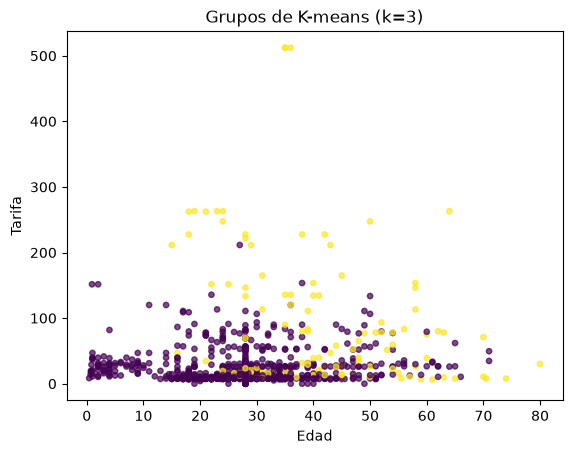

In [11]:
plt.scatter(df['Age'], df['Fare'], c=df['grupo'], s=15, alpha=0.7)
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.title(f'Grupos de K-means (k={K})')
plt.show()


In [12]:
from sklearn.cluster import KMeans
modelo = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
print('Inercia de mi K-means:', round(inercia(X,grupos,centroides),2))
print('Inercia de sklearn K-means:', round(modelo.inertia_,2))




Inercia de mi K-means: 3117.93
Inercia de sklearn K-means: 1785.83


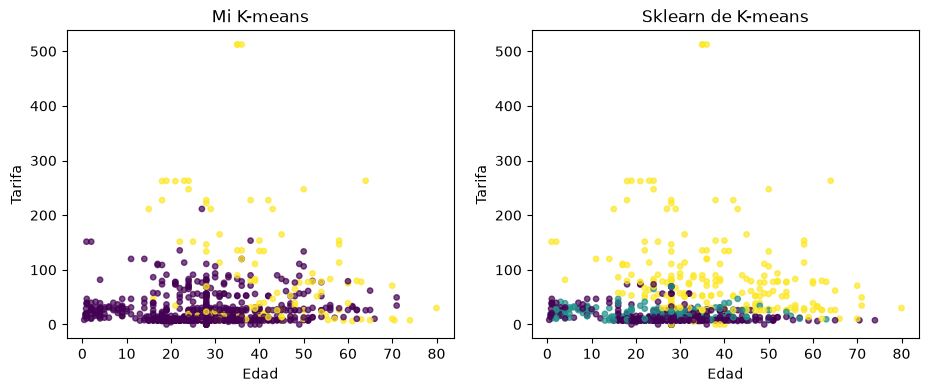

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].scatter(df['Age'], df['Fare'], c=grupos, s=15, alpha=0.7)
ejes[0].set_xlabel('Edad')
ejes[0].set_ylabel('Tarifa')
ejes[0].set_title('Mi K-means')

ejes[1].scatter(df['Age'], df['Fare'], c=modelo.labels_, s=15, alpha=0.7)
ejes[1].set_xlabel('Edad')
ejes[1].set_ylabel('Tarifa')
ejes[1].set_title('Sklearn de K-means')

plt.show()
